# MDCK colony: measured deformation to finite-layer traction

## Problem

Recover signed in-plane traction **t** (Pa) exerted by an MDCK epithelial colony on a bonded elastic layer. Surface displacements **u** (µm) are spatially spread by the elastic Green tensor, so direct displacement images do not reveal local force. The broader paper also studies monolayer stress and cell boundaries; those are distinct unknowns and are explicitly outside this traction-only benchmark.

## Data

We use the entire 48×49 measured PIV field derived from a real 1989×2034 fluorescent-bead image pair before and after cell removal. Values are image pixels, calibrated at0.201 µm/pixel. PIV window100, overlap60 give exact sample pitch40×0.201=8.040000000000001 µm. Canonicalize rows to increasing physical y upward while preserving signed components. This differs from the tutorial's un-reversed image rows and image-size-based approximate grid pitch; we do not claim unchanged tutorial or paper-Fig5 reproduction. Independent original pyTFM elastic functions were rerun on these exact corrected observations. No actual traction truth is available.

## Physics

The Fourier observation is $\widehat{\mathbf u}=G\widehat{\mathbf t}+\widehat{oldsymbol\epsilon}$, where G is the elastic compliance, **k** angular spatial frequency and **n**=**k**/|**k**|. Its inverse stiffness is $K=lpha_\perp(I-\mathbf n\mathbf n^T)+lpha_\parallel\mathbf n\mathbf n^T$. Here I is the2×2 identity, E=49000Pa, ν=.49, h=300µm, $r=|\mathbf k|h$, $lpha_\perp=E|\mathbf k|/[2(1+
u)	anh r]$, and $lpha_\parallel=E|\mathbf k|\gamma/[2(1-
u^2)]$, with $\gamma=[3-4
u+(1-2
u)^2\mathrm{sech}^2r+r^2\mathrm{sech}^2r]/[(3-4
u)	anh r+r\mathrm{sech}^2r]$. These coefficients are Pa/µm. Zero-frequency rigid translation is removed and DC traction fixed to zero.

## Method

Subtract mean displacement, convert to µm, pad bottom/right to50×50, Fourier transform, multiply by explicit local stiffness, inverse transform and crop, then Gaussian smooth with physical sigma6µm. This is a closed-form inverse rather than an iterative optimizer. Finite thickness, infinite half-space, and unsmoothed finite traction are actively computed below; archived upstream values are comparison measurements only.

In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,GRID_PITCH_UM,PIXEL_SIZE_UM
from src.solvers import reconstruct
from src.visualization import review
u=load_data()
t=time.perf_counter();fresh=reconstruct(u);runtime=time.perf_counter()-t
infinite=reconstruct(u,mode='infinite')
unfiltered=reconstruct(u,smoothing_um=0)
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh[None])
np.savez_compressed('notebooks/reference_outputs/cleaned_measurements.npz',reconstruction=fresh[None],infinite=infinite[None],unfiltered=unfiltered[None],runtime_s=runtime)
reference=np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False)
print(f'Fresh full finite-layer inverse: {runtime:.6f}s; output {fresh.shape} Pa')

Fresh full finite-layer inverse: 0.000611s; output (2, 48, 49) Pa


## Results

The first figure shows the measured displacement components and the freshly recovered signed traction components. The second compares the independent upstream finite-layer result, fresh finite-layer result, and fresh half-space result at a common traction-magnitude scale. Vector-difference maps preserve component signs in their computation. The quiver panel shows actual freshly computed vectors. No cached result is used as a reconstruction.

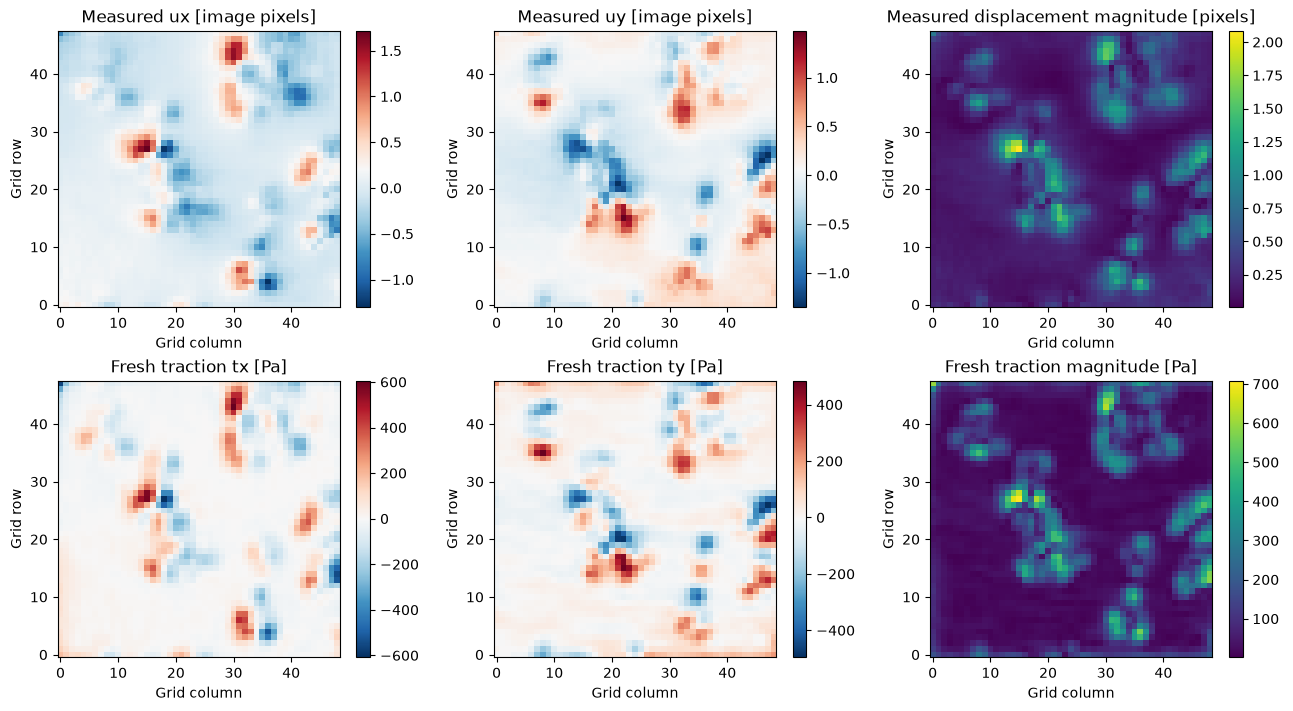

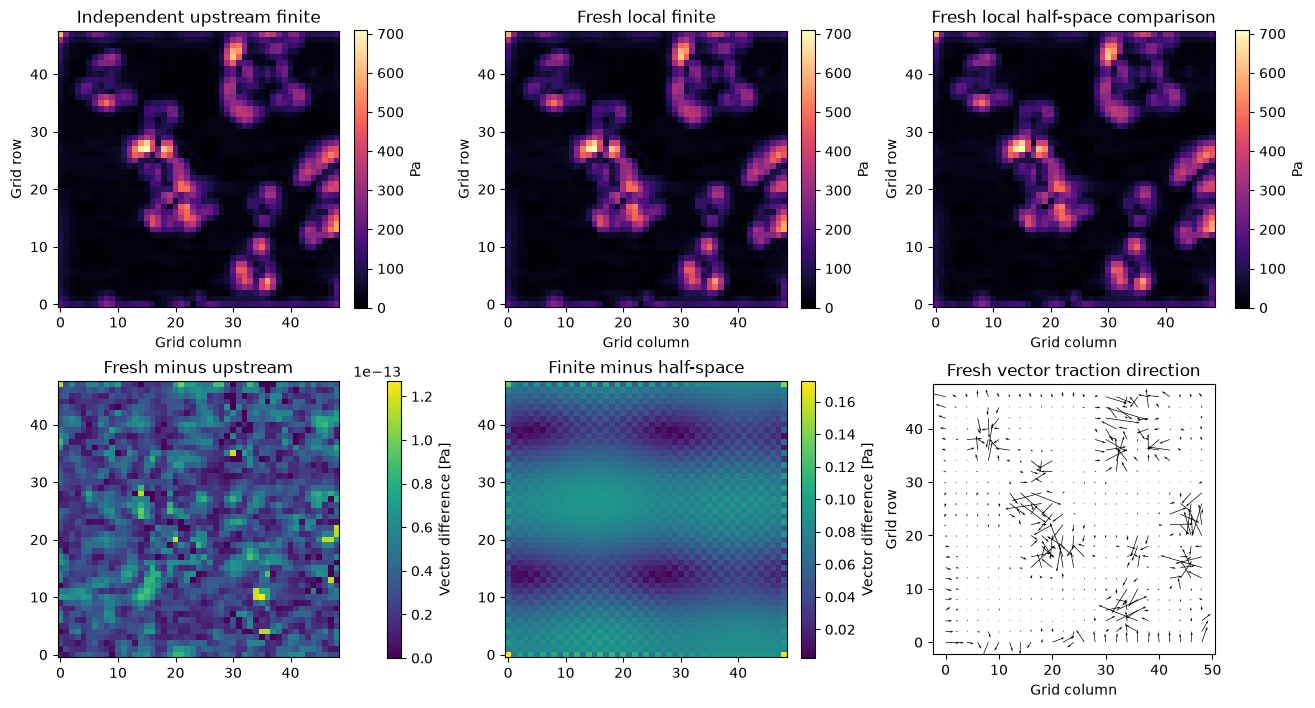

In [2]:
fig1,fig2=review(u,fresh,reference['reconstruction'][0],infinite)
plt.show()

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0,
    "nrmse": 2.1602394498225148e-17
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.99999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    }
  },
  "errors": []
}
Method | NCC vs upstream finite | Dynamic-range NRMSE | RMS traction [Pa]
Independent upstream finite | 1.0 | 0.0 | 95.54680367615819
Fresh finite layer | 1.0 | 2.1602394498225148e-17 | 95.54680367615819
Fresh half-space | 0.9999998922302057 | 3.6809041316999165e-05 | 95.54109427594534
Fresh finite unfiltered | 0.9253356552008623 | 0.045953762408579506 | 130.89951301337615


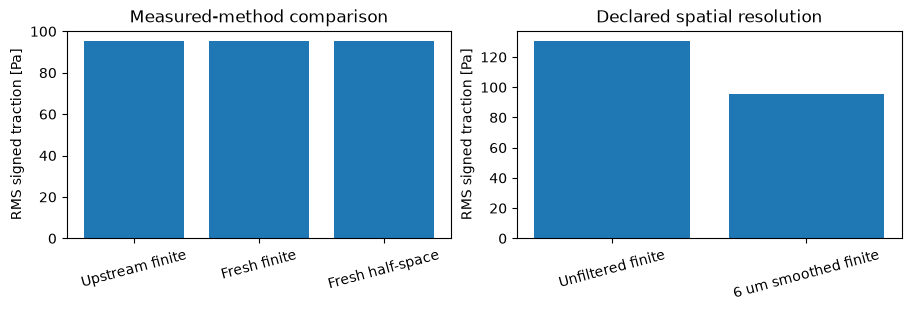

In [3]:
spec=importlib.util.spec_from_file_location('standalone_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,status=judge.evaluate('output/reconstruction.npz');assert status==0,report
print(json.dumps(report,indent=2))
print('Method | NCC vs upstream finite | Dynamic-range NRMSE | RMS traction [Pa]')
for label,a in [('Independent upstream finite',reference['reconstruction'][0]),('Fresh finite layer',fresh),('Fresh half-space',infinite),('Fresh finite unfiltered',unfiltered)]:
    metrics=judge.metrics(a,reference['reconstruction'][0])
    print(label,'|',metrics['ncc'],'|',metrics['nrmse'],'|',np.sqrt(np.mean(a*a)))
fig,axes=plt.subplots(1,2,figsize=(9,3),layout='constrained')
names=['Upstream finite','Fresh finite','Fresh half-space']
values=[reference['reconstruction'][0],fresh,infinite]
axes[0].bar(names,[np.sqrt(np.mean(a*a)) for a in values]);axes[0].set(ylabel='RMS signed traction [Pa]',title='Measured-method comparison')
axes[1].bar(['Unfiltered finite','6 um smoothed finite'],[np.sqrt(np.mean(unfiltered**2)),np.sqrt(np.mean(fresh**2))]);axes[1].set(ylabel='RMS signed traction [Pa]',title='Declared spatial resolution')
for ax in axes:ax.tick_params(axis='x',rotation=15)
plt.show()

## Conclusion

The fresh local finite-layer inverse reproduces the original elastic kernel on the exact canonicalized experimental displacement field. The half-space and unsmoothed comparisons quantify the chosen mechanical model and resolution rather than substituting easier output. Independent spectral positivity, elastic work, compliance roundtrip, rigid-translation invariance and half-space-limit checks accompany numerical parity. Real PIV noise, finite observation support, material-model approximation and unavailable true traction remain limitations. NCC/NRMSE here measure standard-method agreement, not physical ground-truth accuracy.